# Multimodal Stroke Detection Using CT and MRI

**Models:** CT-only ResNet18, MRI-only ResNet18, Dual-branch ResNet18  
**Tasks:** Subject-independent splitting, training, evaluation, Grad-CAM  
**Framework:** PyTorch

> This notebook is a research prototype, not a clinical diagnostic tool. Verify subject IDs and labels before training. Never split images from the same subject across train/validation/test.

## 1. Install dependencies

In [1]:
%pip -q install torch torchvision scikit-learn pandas numpy matplotlib seaborn pillow tqdm opencv-python

## 2. Imports and reproducibility

In [2]:
!pip install -q kaggle
import os
import getpass
import re
import copy
import json
import random
import time
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 3. Configure dataset and output paths


In [3]:
os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Enter Kaggle API token: ")

Enter Kaggle API token: ··········


In [4]:
!kaggle datasets download -d turkertuncer/multimodal-stroke-image-dataset

Dataset URL: https://www.kaggle.com/datasets/turkertuncer/multimodal-stroke-image-dataset
License(s): CC0-1.0
100% 556M/556M [00:05<00:00, 97.7MB/s]



In [5]:
!mkdir -p /content/data
!unzip -q multimodal-stroke-image-dataset.zip -d /content/data
print("Dataset downloaded:", os.path.exists("/content/data"))
print("Files found:", sum(len(files) for _, _, files in os.walk("/content/data")))

Dataset downloaded: True
Files found: 5337


In [6]:
DATA_ROOT = Path("/content/data")

OUTPUT_ROOT = Path("/content/stroke_outputs")
WEIGHTS_DIR = OUTPUT_ROOT / "weights"
RESULTS_DIR = OUTPUT_ROOT / "results"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
assert DATA_ROOT.exists(), f"DATA_ROOT does not exist: {DATA_ROOT}"

## 4. Inspect the directory structure before parsing



In [7]:
all_image_paths = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
print("Images found:", len(all_image_paths))
for p in all_image_paths[:40]:
    print(p.relative_to(DATA_ROOT))

Images found: 5336
deep/test/normalBT/2_1 (10).jpg
deep/test/normalBT/2_1 (10).png
deep/test/normalBT/2_1 (100).jpg
deep/test/normalBT/2_1 (100).png
deep/test/normalBT/2_1 (108).png
deep/test/normalBT/2_1 (109).jpg
deep/test/normalBT/2_1 (109).png
deep/test/normalBT/2_1 (110).jpg
deep/test/normalBT/2_1 (110).png
deep/test/normalBT/2_1 (118).png
deep/test/normalBT/2_1 (119).jpg
deep/test/normalBT/2_1 (119).png
deep/test/normalBT/2_1 (120).jpg
deep/test/normalBT/2_1 (120).png
deep/test/normalBT/2_1 (128).png
deep/test/normalBT/2_1 (129).jpg
deep/test/normalBT/2_1 (129).png
deep/test/normalBT/2_1 (130).jpg
deep/test/normalBT/2_1 (130).png
deep/test/normalBT/2_1 (138).png
deep/test/normalBT/2_1 (139).jpg
deep/test/normalBT/2_1 (139).png
deep/test/normalBT/2_1 (140).jpg
deep/test/normalBT/2_1 (140).png
deep/test/normalBT/2_1 (148).png
deep/test/normalBT/2_1 (149).jpg
deep/test/normalBT/2_1 (149).png
deep/test/normalBT/2_1 (150).jpg
deep/test/normalBT/2_1 (150).png
deep/test/normalBT/2_1 (15

## 5. Build the image manifest


In [8]:
def infer_label(path: Path):
    text = " ".join(part.lower() for part in path.parts)
    name = path.name.lower()
    # Check control/healthy first to avoid accidental substring matches.
    if re.search(r"(^|[^a-z])control([^a-z]|$)|healthy|normal", text):
        return "Control"
    if re.search(r"(^|[^a-z])stroke([^a-z]|$)|ischemi|hemorrhag", text):
        return "Stroke"
    return None

def infer_modality(path: Path):
    text = " ".join(part.lower() for part in path.parts)
    has_ct = bool(re.search(r"(^|[^a-z])ct([^a-z]|$)|computed.?tomography", text))
    has_mri = bool(re.search(r"(^|[^a-z])mri([^a-z]|$)|magnetic.?resonance", text))
    if has_ct and not has_mri:
        return "CT"
    if has_mri and not has_ct:
        return "MRI"
    return None

def extract_subject_id(path: Path):
    # Edit this regex after inspecting actual filenames/folders.
    # Examples matched: subject_001, subject-001, patient12, case_023, sub-001
    text = "/".join(path.parts)
    patterns = [
        r"(?i)(subject|patient|case|sub)[_-]?(\d+)",
        r"(?i)(subject|patient|case|sub)[_-]?([a-z]+\d+)"
    ]
    for pattern in patterns:
        match = re.search(pattern, text)
        if match:
            return f"{match.group(1).lower()}_{match.group(2).lower()}"
    return None

records = []
for path in all_image_paths:
    records.append({
        "path": str(path),
        "label": infer_label(path),
        "modality": infer_modality(path),
        "subject_id": extract_subject_id(path)
    })

manifest = pd.DataFrame(records)
print("Manifest rows:", len(manifest))
display(manifest.head())
print("\nMissing values:")
display(manifest[["label", "modality", "subject_id"]].isna().sum())
print("\nLabel counts:")
display(manifest["label"].value_counts(dropna=False))
print("\nModality counts:")
display(manifest["modality"].value_counts(dropna=False))

Manifest rows: 5336


,path,label,modality,subject_id
0,/content/data/deep/test/normalBT/2_1 (10).jpg,Control,None,None
1,/content/data/deep/test/normalBT/2_1 (10).png,Control,None,None
2,/content/data/deep/test/normalBT/2_1 (100).jpg,Control,None,None
3,/content/data/deep/test/normalBT/2_1 (100).png,Control,None,None
4,/content/data/deep/test/normalBT/2_1 (108).png,Control,None,None



Missing values:


,0
label,670
modality,5336
subject_id,5336



Label counts:


,count
label,
Control,2641
Stroke,2025
None,670



Modality counts:


,count
modality,
None,5336


In [9]:
import re
from pathlib import Path
import pandas as pd
DATA_ROOT = Path("/content/data")
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
def infer_label(path):
    folder = path.parent.name.lower()
    if folder.startswith("normal"):
        return "Control"
    elif folder.startswith("stroke"):
        return "Stroke"
    return None

def infer_modality(path):
    folder = path.parent.name.lower()
    if folder.endswith("bt"):
        return "CT"
    elif folder.endswith("mr"):
        return "MRI"
    return None

def infer_original_split(path):
    folder = path.parent.name
    if folder[0].isupper():
        return "train"
    return "test"

all_image_paths = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

records = []
for path in all_image_paths:
    records.append({
        "path": str(path),
        "label": infer_label(path),
        "modality": infer_modality(path),
        "original_split": infer_original_split(path)
    })

manifest = pd.DataFrame(records)
manifest["label_id"] = manifest["label"].map({"Control": 0, "Stroke": 1})

# Validate metadata
unparsed = manifest[
    manifest[["label", "modality", "original_split", "label_id"]]
    .isna().any(axis=1)
]
print("Total images:", len(manifest))
print("Unparsed images:", len(unparsed))
if len(unparsed):
    display(unparsed.head(20))
    raise ValueError("Metadata extraction failed.")

# Dataset statistics
print("\nLabel distribution:")
display(manifest["label"].value_counts())
print("\nModality distribution:")
display(manifest["modality"].value_counts())
print("\nOriginal split distribution:")
display(manifest["original_split"].value_counts())
print("\nModality vs Label:")
display(pd.crosstab(
    manifest["modality"],
    manifest["label"]
))
print("\nSplit vs Modality:")
display(pd.crosstab(
    manifest["original_split"],
    manifest["modality"]
))

# Save manifest
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
manifest.to_csv(OUTPUT_ROOT / "manifest.csv", index=False)
print("\nManifest successfully created.")

Total images: 5336
Unparsed images: 0

Label distribution:


,count
label,
Stroke,2695
Control,2641



Modality distribution:


,count
modality,
MRI,3110
CT,2226



Original split distribution:


,count
original_split,
train,4009
test,1327



Modality vs Label:


label,Control,Stroke
modality,,
CT,1297,929
MRI,1344,1766



Split vs Modality:


modality,CT,MRI
original_split,,
test,552,775
train,1674,2335



Manifest successfully created.


In [20]:
import re
from pathlib import Path

# Safely extract and re-assign subject_id if it's missing
if "subject_id" not in manifest.columns:
    def extract_subject_id(path_str):
        path = Path(path_str)
        match = re.match(r"^(\d+)_(\d+)", path.stem)
        if match:
            class_code = match.group(1)
            patient_number = match.group(2)
            return f"{class_code}_{patient_number}"
        return None
    manifest["subject_id"] = manifest["path"].apply(extract_subject_id)

print("Unique subjects:", manifest["subject_id"].nunique())
print("\nImages per subject:")
display(
    manifest.groupby("subject_id")
    .agg(
        total_images=("path", "count"),
        modalities=("modality", "nunique"),
        labels=("label", "nunique")
    )
    .head(20)
)

Unique subjects: 4

Images per subject:


,total_images,modalities,labels
subject_id,,,
1_1,929,1,1
1_2,1766,1,1
2_1,1297,1,1
2_2,1344,1,1


In [13]:
manifest["original_split"] = manifest["path"].apply(
    lambda x: Path(x).parts[-3]
)
train_ids = set(
    manifest.loc[
        manifest.original_split == "train",
        "subject_id"
    ]
)
test_ids = set(
    manifest.loc[
        manifest.original_split == "test",
        "subject_id"
    ]
)
print("Original training subjects:", len(train_ids))
print("Original testing subjects:", len(test_ids))
print("Subject overlap:", len(train_ids & test_ids))

Original training subjects: 0
Original testing subjects: 4
Subject overlap: 0


In [14]:
def extract_subject_id(path):
    match = re.match(r"^(\d+)_(\d+)", path.stem)
    if match:
        class_code = match.group(1)
        patient_number = match.group(2)
        return f"{class_code}_{patient_number}"
    return None
manifest["subject_id"] = manifest["path"].apply(
    lambda x: extract_subject_id(Path(x))
)

def infer_original_split(path):
    folder = path.parent.name
    if folder[0].isupper():
        return "train"
    return "test"
manifest["original_split"] = manifest["path"].apply(
    lambda x: infer_original_split(Path(x))
)
print(manifest["original_split"].value_counts())

print("Unique subjects:", manifest["subject_id"].nunique())
display(manifest.groupby(["original_split", "label"]).agg(
        images=("path", "count"),
        subjects=("subject_id", "nunique")
    )
)
subject_modalities = manifest.groupby("subject_id")["modality"].nunique()
print("Subjects with both modalities:",(subject_modalities == 2).sum())
print("Subjects with one modality:",(subject_modalities == 1).sum())

original_split
train    4009
test     1327
Name: count, dtype: int64
Unique subjects: 4


images  subjects
original_split label                    
test           Control     657         2
               Stroke      670         2
train          Control    1984         2
               Stroke     2025         2

Subjects with both modalities: 0
Subjects with one modality: 4


## 6. Subject-independent train/validation/test split

The split is performed on unique subjects, not images. This prevents images from one person appearing in multiple partitions.

In [15]:
from sklearn.model_selection import train_test_split
# Preserve original test partition
original_train = manifest[manifest["original_split"] == "train"].copy()
test_df = manifest[manifest["original_split"] == "test"].copy()

# Split original training data into train and validation
train_df, val_df = train_test_split(
    original_train,
    test_size=0.20,
    random_state=42,
    stratify=original_train["label_id"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
display(pd.crosstab(train_df["modality"], train_df["label"]))

print("\nValidation distribution:")
display(pd.crosstab(val_df["modality"], val_df["label"]))

print("\nTesting distribution:")
display(pd.crosstab(test_df["modality"], test_df["label"]))

Training images: 3207
Validation images: 802
Testing images: 1327

Training distribution:


label,Control,Stroke
modality,,
CT,797,570
MRI,790,1050



Validation distribution:


label,Control,Stroke
modality,,
CT,178,129
MRI,219,276



Testing distribution:


label,Control,Stroke
modality,,
CT,322,230
MRI,335,440


## 7. Modality-Wise Dataset Preparation

The dataset is divided into separate CT and MRI subsets to facilitate independent training and evaluation of deep learning models. Each image retains its corresponding stroke or control label. Since a verified patient-level mapping between CT and MRI images is unavailable, the images are not artificially paired across modalities.

In [16]:
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class StrokeDataset(Dataset):
    def __init__(self, dataframe, modality, transform=None):
        self.df = dataframe[
            dataframe["modality"] == modality
        ].reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(row["label_id"], dtype=torch.float32)
        return image, label

## 8. Image Preprocessing and Dataset Class Implementation

In [17]:
IMG_SIZE = 224
BATCH_SIZE = 16 if DEVICE.type == "cuda" else 8
NUM_WORKERS = 2
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(5),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02), scale=(0.97, 1.03)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class SingleModalityDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(float(row["label_id"]), dtype=torch.float32)
        return image, label

## 9. DataLoaders

In [18]:
def make_single_loaders(modality):
    tr = train_df[train_df.modality == modality]
    va = val_df[val_df.modality == modality]
    te = test_df[test_df.modality == modality]
    if min(len(tr), len(va), len(te)) == 0:
        raise ValueError(f"Empty split for modality {modality}")
    return (
        DataLoader(
            SingleModalityDataset(tr, train_transform),
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda")
        ),
        DataLoader(
            SingleModalityDataset(va, eval_transform),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda")
        ),
        DataLoader(
            SingleModalityDataset(te, eval_transform),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=(DEVICE.type == "cuda")
        )
    )
ct_train_loader, ct_val_loader, ct_test_loader = make_single_loaders("CT")
mri_train_loader, mri_val_loader, mri_test_loader = make_single_loaders("MRI")

print("CT batches:", len(ct_train_loader), len(ct_val_loader), len(ct_test_loader))
print("MRI batches:", len(mri_train_loader), len(mri_val_loader), len(mri_test_loader))

CT batches: 86 20 35
MRI batches: 115 31 49


## 10. Deep Learning Model Architecture and Initialization

In [19]:
def make_resnet18():
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 1)
    return model

ct_model = make_resnet18().to(DEVICE)
mri_model = make_resnet18().to(DEVICE)
print("CT ResNet18 initialized.")
print("MRI ResNet18 initialized.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 54.0MB/s]


CT ResNet18 initialized.
MRI ResNet18 initialized.


## 11. Model Training and Validation Utilities

In [21]:
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 30
PATIENCE = 5

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    all_labels, all_probs = [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).view(-1, 1)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            probs = torch.sigmoid(logits).detach().cpu().numpy().ravel()
            all_probs.extend(probs.tolist())
            all_labels.extend(
                labels.detach().cpu().numpy().ravel().tolist()
            )
    avg_loss = total_loss / len(all_labels)
    preds = (np.array(all_probs) >= 0.5).astype(int)
    accuracy = accuracy_score(all_labels, preds)
    return avg_loss, accuracy

def train_model(model, train_loader, val_loader, save_path, modality):
    counts = train_df[
        train_df["modality"] == modality
    ]["label_id"].value_counts()
    pos_weight = torch.tensor(
        [counts[0] / counts[1]],
        dtype=torch.float32,
        device=DEVICE
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        scheduler.step(val_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Time: {time.time()-start:.1f}s"
        )
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, save_path)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print("Early stopping.")
                break
    model.load_state_dict(best_state)
    return model, history

In [22]:
ct_model, ct_history = train_model(
    ct_model,
    ct_train_loader,
    ct_val_loader,
    OUTPUT_ROOT / "ct_resnet18_best.pth",
    "CT"
)
mri_model, mri_history = train_model(
    mri_model,
    mri_train_loader,
    mri_val_loader,
    OUTPUT_ROOT / "mri_resnet18_best.pth",
    "MRI"
)

Epoch 01/30 | Train Loss: 0.4136 | Val Loss: 0.3691 | Train Acc: 0.8237 | Val Acc: 0.8599 | Time: 19.9s
Epoch 02/30 | Train Loss: 0.1983 | Val Loss: 0.2621 | Train Acc: 0.9305 | Val Acc: 0.9121 | Time: 15.6s
Epoch 03/30 | Train Loss: 0.1911 | Val Loss: 0.1962 | Train Acc: 0.9290 | Val Acc: 0.9479 | Time: 17.6s
Epoch 04/30 | Train Loss: 0.1327 | Val Loss: 0.2020 | Train Acc: 0.9561 | Val Acc: 0.9446 | Time: 15.4s
Epoch 05/30 | Train Loss: 0.0666 | Val Loss: 0.2404 | Train Acc: 0.9832 | Val Acc: 0.9316 | Time: 15.3s
Epoch 06/30 | Train Loss: 0.0718 | Val Loss: 0.1937 | Train Acc: 0.9773 | Val Acc: 0.9349 | Time: 15.3s
Epoch 07/30 | Train Loss: 0.0914 | Val Loss: 0.2727 | Train Acc: 0.9759 | Val Acc: 0.9251 | Time: 15.5s
Epoch 08/30 | Train Loss: 0.0676 | Val Loss: 0.2595 | Train Acc: 0.9773 | Val Acc: 0.9414 | Time: 16.3s
Epoch 09/30 | Train Loss: 0.0665 | Val Loss: 0.1661 | Train Acc: 0.9817 | Val Acc: 0.9479 | Time: 15.9s
Epoch 10/30 | Train Loss: 0.0460 | Val Loss: 0.2382 | Train Acc:

## 12. Training the CT and MRI Classification Models
Training can take time. Save checkpoints are written to `stroke_outputs/weights/`.

In [23]:
ct_model, ct_history = train_model(
    ct_model,
    ct_train_loader,
    ct_val_loader,
    WEIGHTS_DIR / "ct_model.pth",
    modality="CT"
)

mri_model, mri_history = train_model(
    mri_model,
    mri_train_loader,
    mri_val_loader,
    WEIGHTS_DIR / "mri_model.pth",
    modality="MRI"
)

Epoch 01/30 | Train Loss: 0.0970 | Val Loss: 0.3067 | Train Acc: 0.9737 | Val Acc: 0.9381 | Time: 15.6s
Epoch 02/30 | Train Loss: 0.0715 | Val Loss: 0.1613 | Train Acc: 0.9773 | Val Acc: 0.9446 | Time: 16.7s
Epoch 03/30 | Train Loss: 0.0402 | Val Loss: 0.2852 | Train Acc: 0.9890 | Val Acc: 0.9316 | Time: 18.1s
Epoch 04/30 | Train Loss: 0.0175 | Val Loss: 0.2152 | Train Acc: 0.9949 | Val Acc: 0.9511 | Time: 16.9s
Epoch 05/30 | Train Loss: 0.0568 | Val Loss: 0.2016 | Train Acc: 0.9817 | Val Acc: 0.9577 | Time: 15.5s
Epoch 06/30 | Train Loss: 0.0428 | Val Loss: 0.2422 | Train Acc: 0.9854 | Val Acc: 0.9381 | Time: 16.4s
Epoch 07/30 | Train Loss: 0.0307 | Val Loss: 0.1861 | Train Acc: 0.9905 | Val Acc: 0.9316 | Time: 16.5s
Early stopping.
Epoch 01/30 | Train Loss: 0.0324 | Val Loss: 0.0732 | Train Acc: 0.9864 | Val Acc: 0.9737 | Time: 21.6s
Epoch 02/30 | Train Loss: 0.0337 | Val Loss: 0.1002 | Train Acc: 0.9870 | Val Acc: 0.9657 | Time: 23.3s
Epoch 03/30 | Train Loss: 0.0426 | Val Loss: 0.0

## 13. Training Performance Visualization

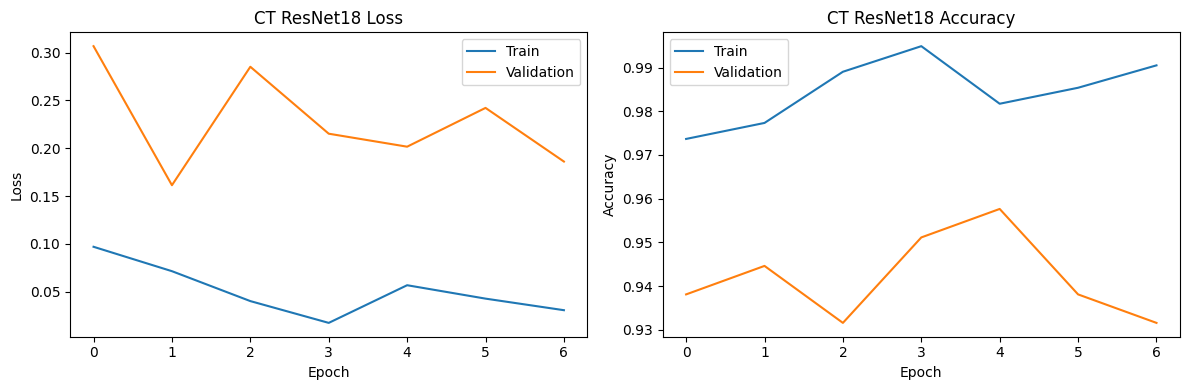

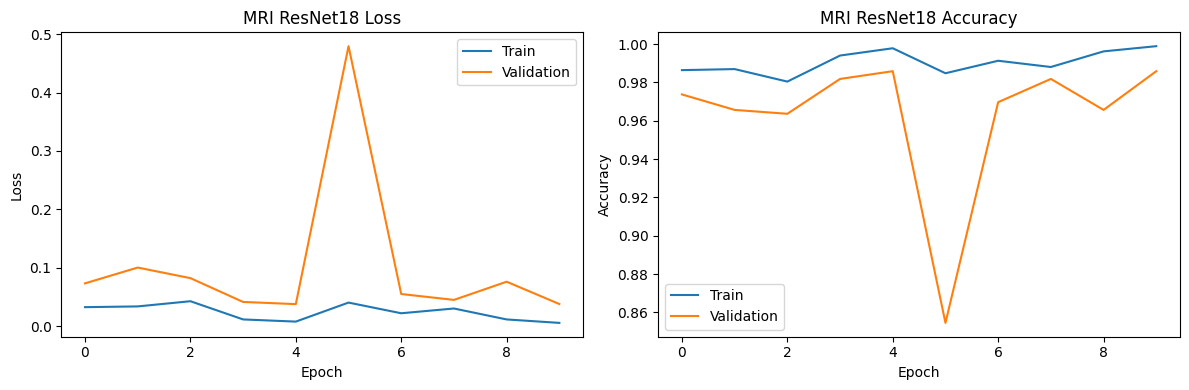

In [24]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
plot_history(ct_history, "CT ResNet18")
plot_history(mri_history, "MRI ResNet18")

## 14. Model Evaluation and Performance Comparison

In [25]:
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    y_true, y_prob = [], []
    for images, labels in loader:
        images = images.to(DEVICE)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu().numpy().ravel()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.numpy().ravel().astype(int).tolist())
    return np.array(y_true), np.array(y_prob)

def evaluate_predictions(y_true, y_prob, name):
    y_pred = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": (tn / (tn + fp) if (tn + fp) else 0.0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": (roc_auc_score(y_true, y_prob)
            if len(np.unique(y_true)) == 2
            else np.nan
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }
    print(f"\n{name}")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Control", "Stroke"],
            zero_division=0
        )
    )
    return metrics, y_pred

# CT Model Predictions
ct_y, ct_prob = collect_predictions(ct_model, ct_test_loader)

# MRI Model Predictions
mri_y, mri_prob = collect_predictions(mri_model, mri_test_loader)

# Evaluate CT Model
ct_metrics, ct_pred = evaluate_predictions(ct_y, ct_prob, "CT-only ResNet18")

# Evaluate MRI Model
mri_metrics, mri_pred = evaluate_predictions(mri_y, mri_prob, "MRI-only ResNet18")

# Performance Comparison
results = pd.DataFrame([ct_metrics, mri_metrics])
display(results)

# Save Results
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(
    RESULTS_DIR / "performance_comparison.csv",
    index=False
)
print("Performance comparison saved successfully.")


CT-only ResNet18
              precision    recall  f1-score   support

     Control       0.93      0.97      0.95       322
      Stroke       0.96      0.90      0.93       230

    accuracy                           0.94       552
   macro avg       0.95      0.94      0.94       552
weighted avg       0.94      0.94      0.94       552


MRI-only ResNet18
              precision    recall  f1-score   support

     Control       0.95      0.99      0.96       335
      Stroke       0.99      0.96      0.97       440

    accuracy                           0.97       775
   macro avg       0.97      0.97      0.97       775
weighted avg       0.97      0.97      0.97       775



,Model,Accuracy,Precision,Sensitivity,Specificity,F1-score,ROC-AUC,TN,FP,FN,TP
0,CT-only ResNet18,0.943841,0.958525,0.904348,0.972050,0.930649,0.985323,313,9,22,208
1,MRI-only ResNet18,0.969032,0.988263,0.956818,0.985075,0.972286,0.996682,330,5,19,421


Performance comparison saved successfully.


## 15. Confusion Matrices and ROC Curve Analysis

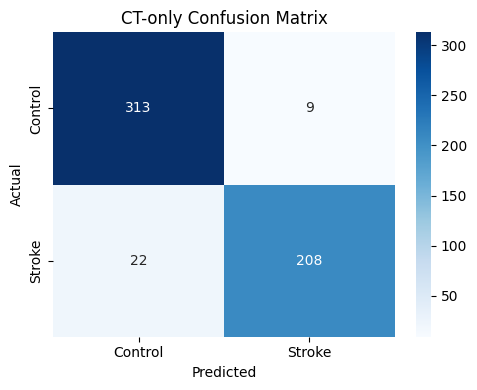

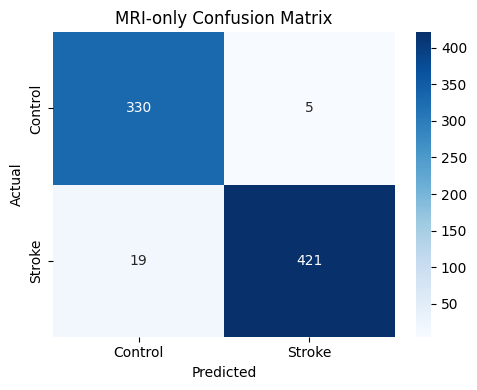

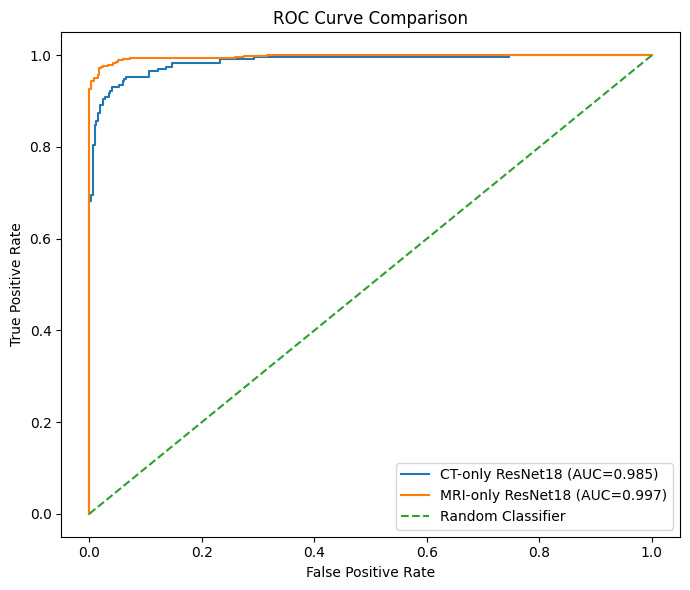

In [26]:
def plot_confusion(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Control", "Stroke"],
        yticklabels=["Control", "Stroke"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=200)
    plt.show()

# Confusion Matrices
plot_confusion(ct_y, ct_pred, "CT-only Confusion Matrix", "ct_confusion.png")
plot_confusion(mri_y, mri_pred, "MRI-only Confusion Matrix", "mri_confusion.png")

# ROC Curve Comparison
plt.figure(figsize=(7, 6))
for y, prob, label in [
    (ct_y, ct_prob, "CT-only ResNet18"),
    (mri_y, mri_prob, "MRI-only ResNet18")
]:
    fpr, tpr, _ = roc_curve(y, prob)
    auc_value = roc_auc_score(y, prob)
    plt.plot(
        fpr,
        tpr,
        label=f"{label} (AUC={auc_value:.3f})"
    )
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_comparison.png", dpi=200)
plt.show()

## 16. Grad-CAM

Grad-CAM is computed independently for each ResNet18 branch. For the multimodal model, the selected modality is passed through its corresponding branch while the other modality is held fixed. The heatmap indicates model-sensitive regions; it is not proof that the highlighted region is medically causal.

In [27]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._save_activation)
        self.backward_handle = target_layer.register_full_backward_hook(self._save_gradient)
    def _save_activation(self, module, inputs, output):
        self.activations = output.detach()
    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    def generate(self, image):
        self.model.zero_grad(set_to_none=True)
        output = self.model(image)
        score = output[:, 0].sum()
        score.backward()
        if self.gradients is None or self.activations is None:
            raise RuntimeError("Grad-CAM gradients or activations missing.")
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = torch.nn.functional.interpolate(
            cam,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )
        cam = cam[0, 0].cpu().numpy()
        cam = (
            (cam - cam.min()) /
            (cam.max() - cam.min() + 1e-8)
        )
        return cam
    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()

def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    return img.permute(1, 2, 0).numpy().clip(0, 1)

def show_cam(image_tensor, cam, title):
    image = denormalize(image_tensor)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(image)
    plt.imshow(cam, cmap="jet", alpha=0.40)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### 16A. Grad-CAM for CT-only and MRI-only models

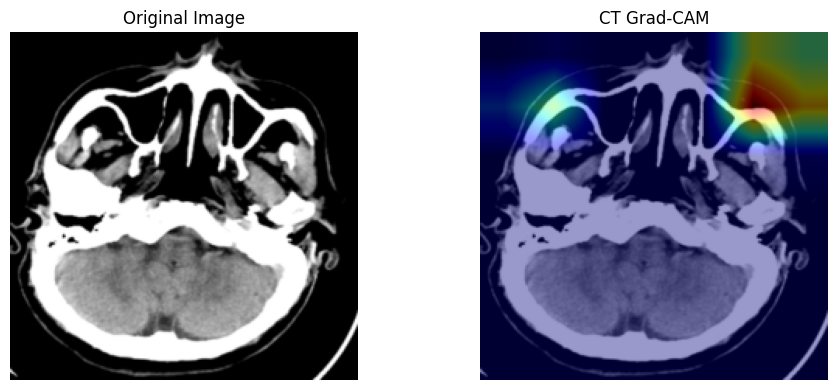

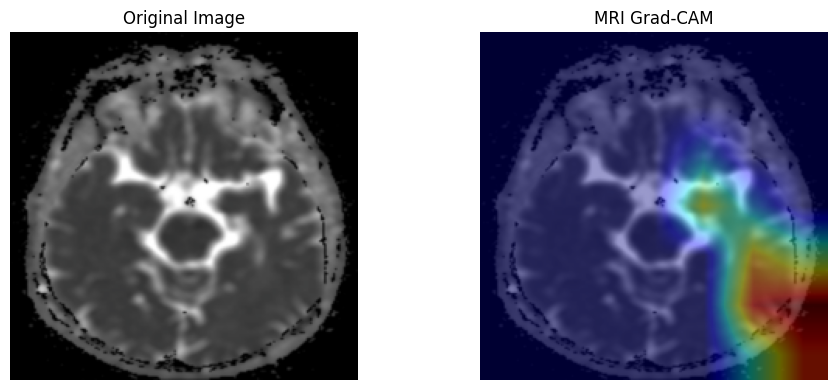

In [28]:
# Select one test image from each modality
ct_images, ct_labels = next(iter(ct_test_loader))
mri_images, mri_labels = next(iter(mri_test_loader))

# CT Grad-CAM
ct_model.eval()
ct_cam = GradCAM(ct_model, ct_model.layer4[-1])
ct_input = ct_images[0:1].to(DEVICE)
ct_heatmap = ct_cam.generate(ct_input)
show_cam(ct_images[0], ct_heatmap, "CT Grad-CAM")
ct_cam.close()

# MRI Grad-CAM
mri_model.eval()
mri_cam = GradCAM(mri_model, mri_model.layer4[-1])
mri_input = mri_images[0:1].to(DEVICE)
mri_heatmap = mri_cam.generate(mri_input)
show_cam(mri_images[0], mri_heatmap, "MRI Grad-CAM")
mri_cam.close()

### 16B. Comparative Grad-CAM Analysis of CT and MRI Models

This section extends the Grad-CAM analysis by examining the regions of interest identified by the independently trained CT and MRI ResNet18 models.

Representative Stroke and Control images are selected from both test datasets. Grad-CAM heatmaps are generated using the final convolutional layers of the respective models and overlaid on the original brain images.

The resulting visualizations facilitate qualitative comparison of the spatial features learned by the two imaging modalities during binary stroke classification.

## 17. Saving Final Model Checkpoints and Metadata

In [29]:
# Save final model checkpoints
torch.save(ct_model.state_dict(), WEIGHTS_DIR / "ct_model.pth")
torch.save(mri_model.state_dict(), WEIGHTS_DIR / "mri_model.pth")

# Save model metadata
metadata = {
    "image_size": IMG_SIZE,
    "classes": {"Control": 0, "Stroke": 1},
    "models": {"CT": "ResNet18", "MRI": "ResNet18"},
    "task": "Binary Stroke Classification",
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "seed": SEED
}

with open(OUTPUT_ROOT / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Display saved files
print("Saved files:")
for p in OUTPUT_ROOT.rglob("*"):
    if p.is_file():
        print(p, f"({p.stat().st_size / (1024**2):.2f} MB)")

Saved files:
/content/stroke_outputs/mri_resnet18_best.pth (42.71 MB)
/content/stroke_outputs/ct_resnet18_best.pth (42.71 MB)
/content/stroke_outputs/model_metadata.json (0.00 MB)
/content/stroke_outputs/manifest.csv (0.38 MB)
/content/stroke_outputs/weights/mri_model.pth (42.71 MB)
/content/stroke_outputs/weights/ct_model.pth (42.71 MB)
/content/stroke_outputs/results/performance_comparison.csv (0.00 MB)
/content/stroke_outputs/results/mri_confusion.png (0.04 MB)
/content/stroke_outputs/results/roc_comparison.png (0.09 MB)
/content/stroke_outputs/results/ct_confusion.png (0.04 MB)


## 18. Export results

In Google Colab, download the output directory as a ZIP. Keep the manifest and split files with the model weights so the experiment can be reproduced.

In [30]:
import shutil
zip_path = shutil.make_archive("/content/stroke_outputs", "zip", root_dir=str(OUTPUT_ROOT))
print("Created:", zip_path)

# Download the archive in Google Colab
from google.colab import files
files.download(zip_path)

Created: /content/stroke_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Important methodological notes

1. Confirm the subject ID parser against the real folder/file naming convention. Incorrect IDs invalidate the split.
2. The current multimodal pairing is deterministic slice cycling within a subject. It is not anatomical registration and should be described accurately in the report.
3. The paired multimodal test set may contain fewer subjects than either single-modality test set because only subjects with both modalities are eligible.
4. For a fair comparison, consider evaluating CT-only and MRI-only models on the same paired-subject test cohort as an additional analysis.
5. The notebook currently uses image-level metrics. For stronger subject-level reporting, aggregate each subject's slice probabilities (for example, mean probability) and compute metrics once per subject.
6. This model is experimental and must not be used to make clinical decisions.